In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("MIT-805-Group-Assignment")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "6g")
    .getOrCreate()
)
sc = spark.sparkContext
spark

In [3]:
# Libraries
from pyspark.sql.functions import col, unix_timestamp, year, month, hour, when, date_format, to_date, count, sum
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt
import seaborn as sns
import glob

In [4]:
def load_taxi_data(path):
    return spark.read.parquet(path)

def transform_taxi_data(df):
    return (df
        .select(
            col("VendorID"),
            col("tpep_pickup_datetime"),
            col("tpep_dropoff_datetime"),
            col("passenger_count"),
            col("trip_distance"),
            col("PULocationID"),
            col("DOLocationID"),
            col("fare_amount"),
            col("payment_type"),
            col("tip_amount"),
            col("RatecodeID"),
            col("total_amount")
        )
        .withColumn(
            "trip_duration_minutes",
            (unix_timestamp(col("tpep_dropoff_datetime")) - unix_timestamp(col("tpep_pickup_datetime"))) / 60
        )
        .withColumn("day_of_week", date_format(col("tpep_pickup_datetime"), "EEEE"))
        .withColumn("year", year(col("tpep_pickup_datetime")))
        .withColumn("month", date_format(col("tpep_pickup_datetime"), "MMM"))
        .withColumn(
            "time_of_day",
            when(hour(col("tpep_pickup_datetime")).between(5, 11), "Morning")
            .when(hour(col("tpep_pickup_datetime")).between(12, 17), "Day")
            .otherwise("Night")
        )
        .withColumn("pickup_date",
                    to_date(col("tpep_pickup_datetime"))
                    )
        .withColumn("pickup_hour",
                    hour(col("tpep_pickup_datetime"))
                    )
        .withColumn(
            "payment_type_desc",
            when(col("payment_type") == 1, "Credit Card")
            .when(col("payment_type") == 2, "Cash")
            .when(col("payment_type") == 3, "No Charge")
            .when(col("payment_type") == 4, "Dispute")
            .when(col("payment_type") == 5, "Unknown")
            .otherwise("Other")
        )
        .withColumn(
            "rate_code_desc",
            when(col("RatecodeID") == 1, "Standard Rate")
            .when(col("RatecodeID") == 2, "JFK")
            .when(col("RatecodeID") == 3, "Newark")
            .when(col("RatecodeID") == 4, "Nassau or Westchester")
            .when(col("RatecodeID") == 5, "Negotiated Fare")
            .when(col("RatecodeID") == 6, "Group Ride")
            .otherwise("Other")
        )
        .drop("tpep_dropoff_datetime", "RatecodeID", "payment_type")
    )

def clean_and_cache_taxi_data(df):
    df_clean = df.filter(
        (col("trip_distance") > 0) &
        (col("fare_amount") > 0) &
        (col("passenger_count") > 0)
    ).cache()
    df_clean.count()  # trigger cache
    return df_clean

def process_monthly_file(path):
    df = load_taxi_data(path)
    df = transform_taxi_data(df)
    df = clean_and_cache_taxi_data(df)
    return df

# ----------------------------
# Process 2016 and 2017 Files
# ----------------------------

# Get all parquet files for 2016 and 2017 which is 3.2 GB
files_2016 = glob.glob("/content/drive/My Drive/Working_data/yellow_tripdata_2016-*.parquet")
files_2017 = glob.glob("/content/drive/My Drive/Working_data/yellow_tripdata_2017-*.parquet")

# Zones and borrorws look up table
zones = spark.read.csv("/content/drive/My Drive/Working_data/taxi_zone_lookup.csv", header=True)

# Process and union 2016
df_2016 = None
for f in sorted(files_2016):
    print(f"Processing {f}...")
    df_month = process_monthly_file(f)
    df_2016 = df_month if df_2016 is None else df_2016.unionByName(df_month)

# Process and union 2017
df_2017 = None
for f in sorted(files_2017):
    print(f"Processing {f}...")
    df_month = process_monthly_file(f)
    df_2017 = df_month if df_2017 is None else df_2017.unionByName(df_month)

# Combine both years
df_all = df_2016.unionByName(df_2017)

# Join with zones.
df_all = (
    df_all
    .join(
        zones,
        df_all.PULocationID == zones.LocationID,
        "left"
    )
)

# ----------------------------
# Inspect Final Dataset
# ----------------------------
df_all.printSchema()
print("Final record count:", df_all.count())

Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-01.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-02.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-03.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-04.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-05.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-06.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-07.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-08.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-09.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-10.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-11.parquet...
Processing /content/drive/My Drive/Working_data/yellow_tripdata_2016-12.parquet...
Proc

In [5]:

df_all.show(5)

+--------+--------------------+---------------+-------------+------------+------------+-----------+----------+------------+---------------------+-----------+----+-----+-----------+-----------+-----------+-----------------+--------------+----------+---------+--------------------+------------+
|VendorID|tpep_pickup_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|fare_amount|tip_amount|total_amount|trip_duration_minutes|day_of_week|year|month|time_of_day|pickup_date|pickup_hour|payment_type_desc|rate_code_desc|LocationID|  Borough|                Zone|service_zone|
+--------+--------------------+---------------+-------------+------------+------------+-----------+----------+------------+---------------------+-----------+----+-----+-----------+-----------+-----------+-----------------+--------------+----------+---------+--------------------+------------+
|       1| 2016-01-01 00:12:22|              1|          3.2|          48|         262|       14.0|      3.06|       18.3

# Mapping and Transformation: 3 Marks

## Create mapped records

In [6]:
mapped_df = (
    df_all
    .select(col("Zone").alias("pickup_zone"),
            col("Borough").alias("pickup_borough"),
            "time_of_day",
            "day_of_week",
            "trip_distance",
            "trip_duration_minutes",
            "fare_amount",
            "tip_amount",
            "total_amount",
            "passenger_count"
    )
)
mapped_df.show(5)

+--------------------+--------------+-----------+-----------+-------------+---------------------+-----------+----------+------------+---------------+
|         pickup_zone|pickup_borough|time_of_day|day_of_week|trip_distance|trip_duration_minutes|fare_amount|tip_amount|total_amount|passenger_count|
+--------------------+--------------+-----------+-----------+-------------+---------------------+-----------+----------+------------+---------------+
|        Clinton East|     Manhattan|      Night|     Friday|          3.2|   16.866666666666667|       14.0|      3.06|       18.36|              1|
|        Midtown East|     Manhattan|      Night|     Friday|          1.0|                13.65|        9.5|       0.0|        10.8|              2|
|West Chelsea/Huds...|     Manhattan|      Night|     Friday|          0.9|    6.333333333333333|        6.0|       0.0|         7.3|              1|
|         Murray Hill|     Manhattan|      Night|     Friday|          0.8|                 4.65|   

## Shuffle and Grouping: 3 Marks

In [7]:
from pyspark.sql.functions import col, count, sum, avg, round
summary_agg_df = (
    mapped_df
    .groupBy(
        "pickup_zone",
        "pickup_borough",
        "time_of_day"
    )
    .agg(
        count("*").alias("trip_count"),
        round(sum("total_amount"),2).alias("total_revenue"),
        round(avg("trip_distance"),2).alias("average_trip_distance"),
        round(avg("trip_duration_minutes"),2).alias("average_trip_duration")
    )
    .orderBy("total_revenue", ascending=False)
).cache()

print("Record count:", summary_agg_df.count())

Record count: 784


## Results

In [8]:
summary_agg_df.show(10, False)

+-------------------------+--------------+-----------+----------+--------------+---------------------+---------------------+
|pickup_zone              |pickup_borough|time_of_day|trip_count|total_revenue |average_trip_distance|average_trip_duration|
+-------------------------+--------------+-----------+----------+--------------+---------------------+---------------------+
|JFK Airport              |Queens        |Night      |2534493   |1.4053901926E8|19.36                |37.65                |
|JFK Airport              |Queens        |Day        |1910263   |1.1082053243E8|20.89                |36.44                |
|LaGuardia Airport        |Queens        |Night      |2585807   |1.044469449E8 |9.64                 |28.47                |
|LaGuardia Airport        |Queens        |Day        |2222646   |9.914889395E7 |12.23                |37.5                 |
|East Village             |Manhattan     |Night      |4816597   |7.152765325E7 |2.86                 |16.05                |


DAG

In [9]:
summary_agg_df.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- InMemoryTableScan [pickup_zone#33744, pickup_borough#33745, time_of_day#45, trip_count#42420L, total_revenue#42421, average_trip_distance#42422, average_trip_duration#42423]
      +- InMemoryRelation [pickup_zone#33744, pickup_borough#33745, time_of_day#45, trip_count#42420L, total_revenue#42421, average_trip_distance#42422, average_trip_duration#42423], StorageLevel(disk, memory, deserialized, 1 replicas)
            +- AdaptiveSparkPlan isFinalPlan=true
               +- == Final Plan ==
                  ResultQueryStage 27
                  +- *(4) Sort [total_revenue#42421 DESC NULLS LAST], true, 0
                     +- ShuffleQueryStage 26
                        +- Exchange rangepartitioning(total_revenue#42421 DESC NULLS LAST, 8), ENSURE_REQUIREMENTS, [plan_id=3922]
                           +- *(3) HashAggregate(keys=[pickup_zone#33744, pickup_borough#33745, time_of_day#45], functions=[count(1), sum(total_amount#37)

In [10]:
summary_agg_pd = summary_agg_df.toPandas()

# Visualizations

### Zone analysis

/tmp/ipykernel_1477/3329737737.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


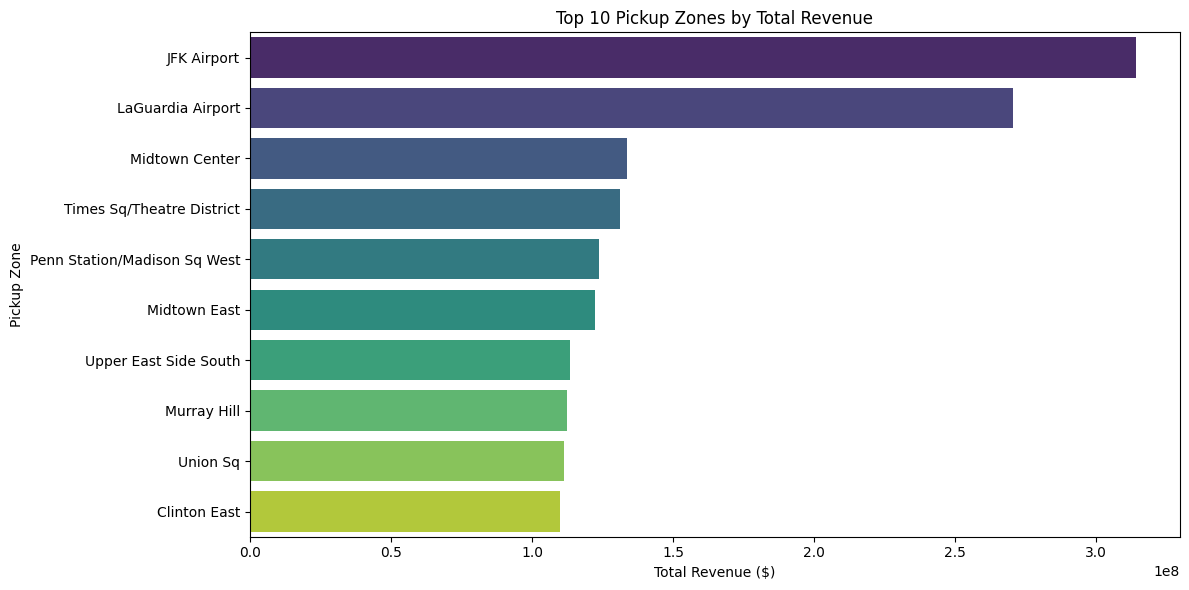

In [11]:
# Top zones by Total Revenue
top_revenue = (
    summary_agg_pd
    .groupby("pickup_zone")["total_revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    x=top_revenue.values,
    y=top_revenue.index,
    palette="viridis"
)

plt.title("Top 10 Pickup Zones by Total Revenue")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Pickup Zone")
plt.tight_layout()
plt.show()

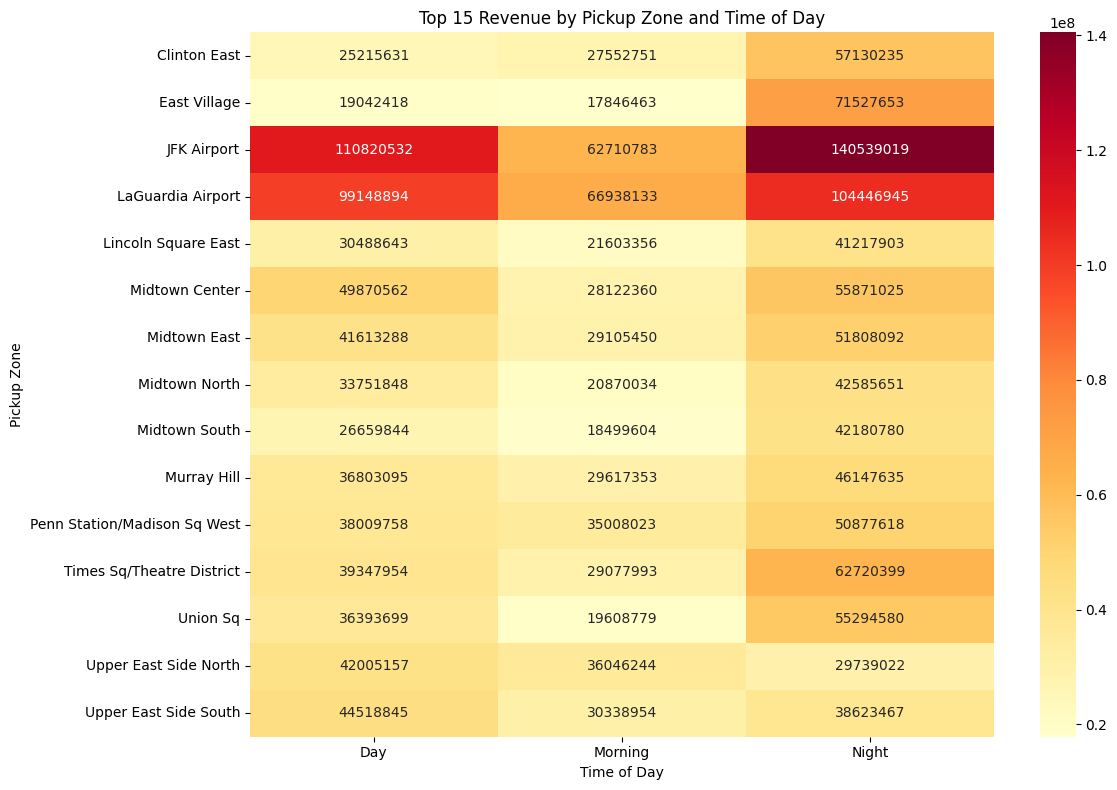

In [12]:
top_zones = (
    summary_agg_pd
    .groupby("pickup_zone")["total_revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .index
)

heatmap_df = summary_agg_pd[
    summary_agg_pd["pickup_zone"].isin(top_zones)
]

pivot_table = heatmap_df.pivot_table(
    values="total_revenue",
    index="pickup_zone",
    columns="time_of_day",
    aggfunc="sum"
)

plt.figure(figsize=(12,8))

sns.heatmap(
    pivot_table,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f"
)

plt.title("Top 15 Revenue by Pickup Zone and Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Pickup Zone")
plt.tight_layout()
plt.savefig(
"/content/drive/My Drive/Working_data/top_15_revenue_heatmap_millions.png",
dpi=600,
bbox_inches="tight"
)
plt.show()

/tmp/ipykernel_1477/4241650564.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


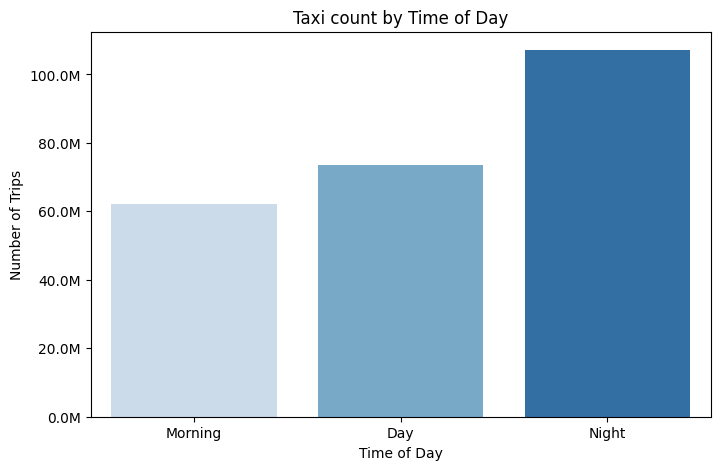

In [13]:
demand_time = (
    summary_agg_pd
    .groupby("time_of_day")["trip_count"]
    .sum()
    .reset_index()
)

order = ["Morning", "Day", "Night"]

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=demand_time,
    x="time_of_day",
    y="trip_count",
    order=order,
    palette="Blues"
)
ax.yaxis.set_major_formatter(
FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')
)

plt.title("Taxi count by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Number of Trips")
plt.savefig(
"/content/drive/My Drive/Working_data/Taxi_demand_by_day.png",
dpi=600,
bbox_inches="tight"
)
plt.show()

/tmp/ipykernel_1477/2769615494.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


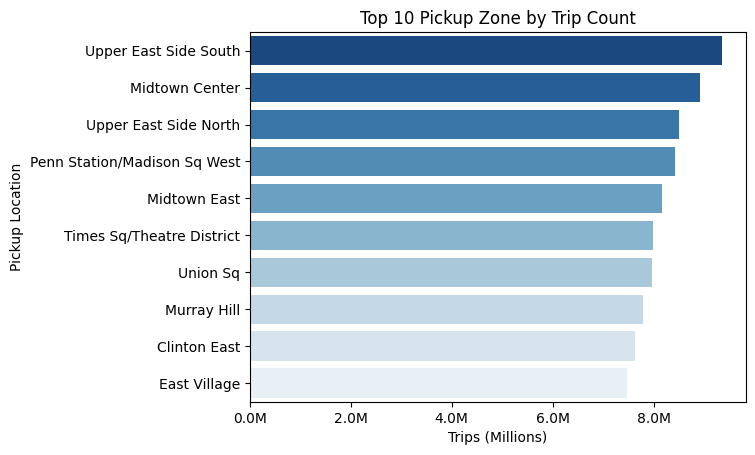

In [14]:
top_pickups = (
    summary_agg_pd
    .groupby("pickup_zone")["trip_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

ax = sns.barplot(
    data=top_pickups,
    x="trip_count",
    y="pickup_zone",
    palette="Blues_r"
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')
)

plt.title("Top 10 Pickup Zone by Trip Count")
plt.xlabel("Trips (Millions)")
plt.ylabel("Pickup Location")
plt.show()

/tmp/ipykernel_1477/1191240095.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


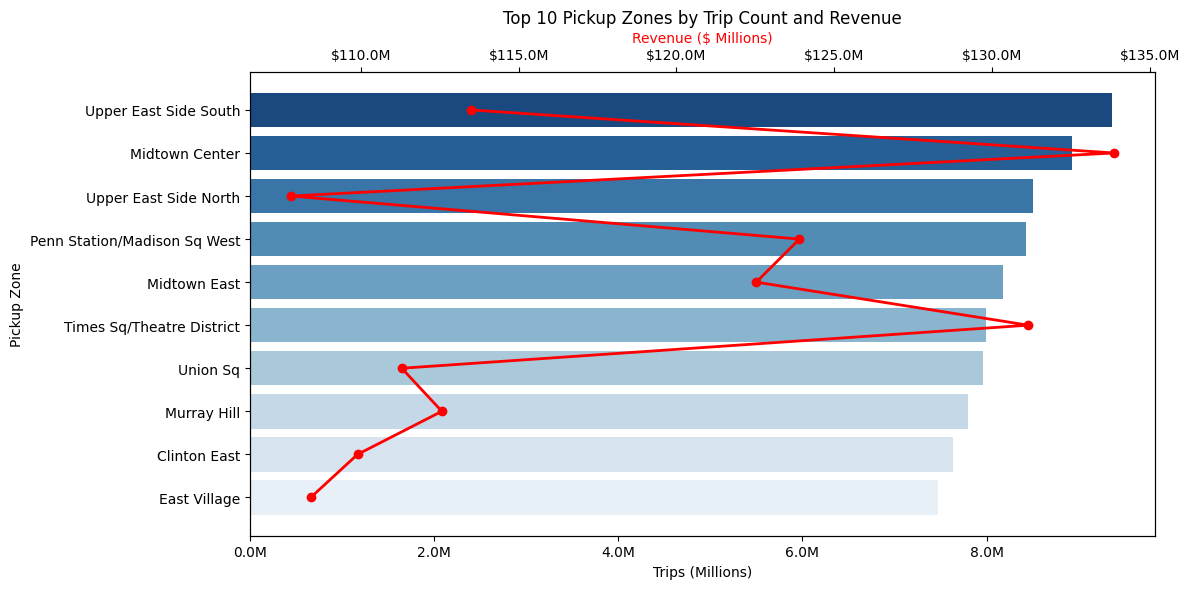

In [15]:

top_pickups = (
    summary_agg_pd
    .groupby("pickup_zone")
    .agg({
        "trip_count": "sum",
        "total_revenue": "sum"
    })
    .reset_index()
    .sort_values("trip_count", ascending=False)
    .head(10)
)

fig, ax1 = plt.subplots(figsize=(12,6))

# Trip count bars
sns.barplot(
    data=top_pickups,
    x="trip_count",
    y="pickup_zone",
    palette="Blues_r",
    ax=ax1
)

ax1.set_xlabel("Trips (Millions)")
ax1.set_ylabel("Pickup Zone")

ax1.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')
)

# Revenue axis
ax2 = ax1.twiny()

ax2.plot(
    top_pickups["total_revenue"],
    top_pickups["pickup_zone"],
    color="red",
    marker="o",
    linewidth=2
)

ax2.set_xlabel("Revenue ($ Millions)", color="red")

ax2.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x/1e6:.1f}M')
)

plt.title("Top 10 Pickup Zones by Trip Count and Revenue")
plt.tight_layout()
# Save plot
plt.savefig("/content/drive/My Drive/Working_data/top_10_pickup_zones_demand_revenue.png", dpi=300)
plt.show()

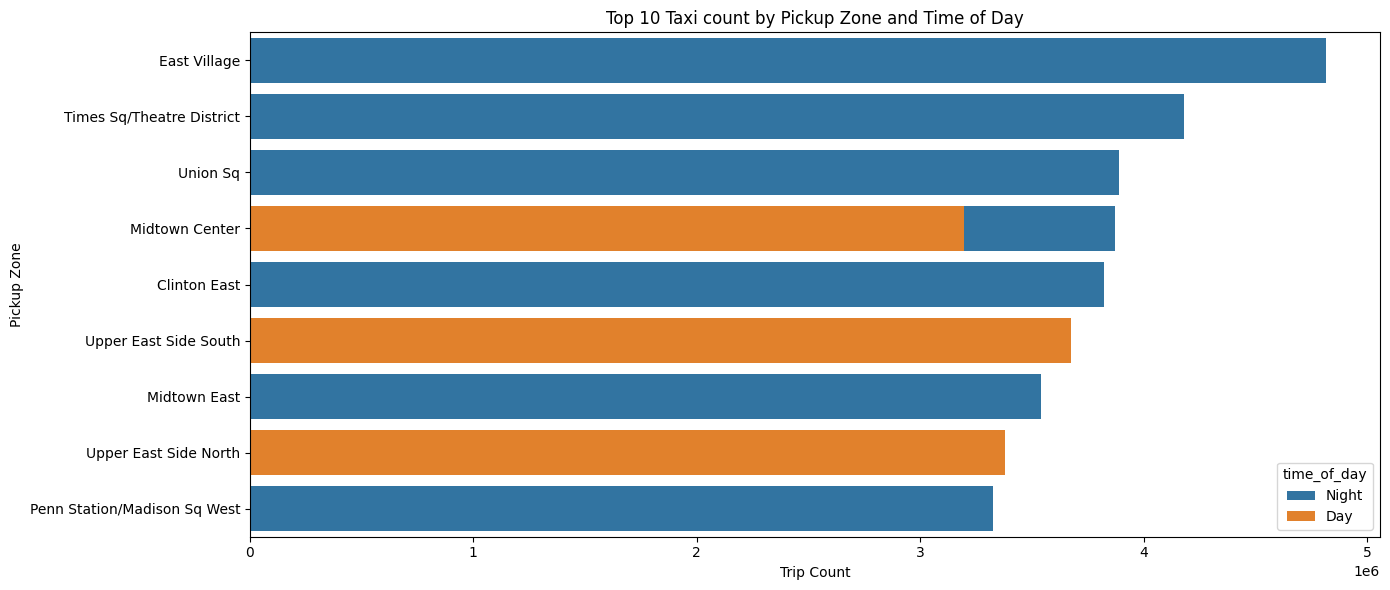

In [16]:
top_zone_day_demand = (
    summary_agg_pd
    .groupby(["pickup_zone", "time_of_day"])["trip_count"]
    .sum()
    .reset_index()
    .sort_values("trip_count", ascending=False)
    .head(10)
)

plt.figure(figsize=(14,6))

sns.barplot(
    data=top_zone_day_demand,
    x="trip_count",
    y="pickup_zone",
    hue="time_of_day",
    dodge=False
)

plt.title("Top 10 Taxi count by Pickup Zone and Time of Day")
plt.xlabel("Trip Count")
plt.ylabel("Pickup Zone")

plt.tight_layout()
plt.show()

## Boroughs

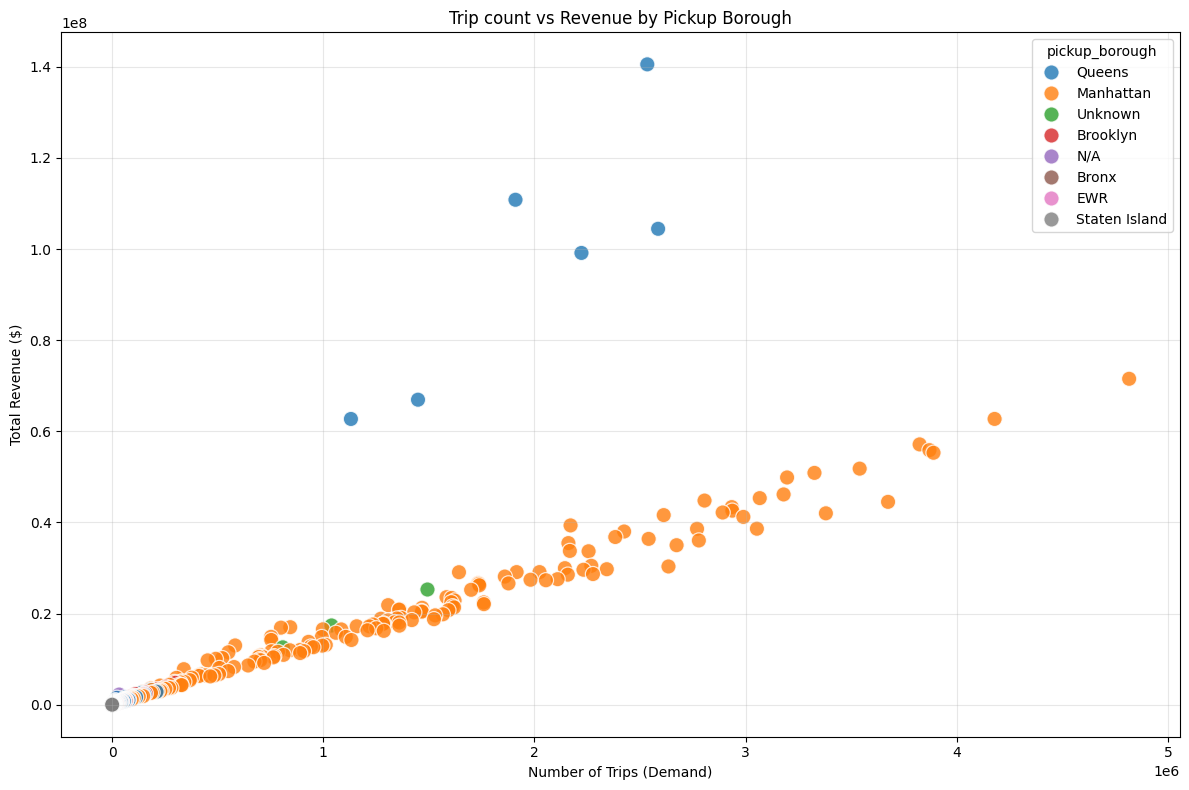

In [17]:
# Plot
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=summary_agg_pd,
    x="trip_count",
    y="total_revenue",
    hue="pickup_borough",
    s=120,
    alpha=0.8
)

plt.title("Trip count vs Revenue by Pickup Borough")
plt.xlabel("Number of Trips (Demand)")
plt.ylabel("Total Revenue ($)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
"/content/drive/My Drive/Working_data/trip_demand_vs_revenue_borough.png",
dpi=600,
bbox_inches="tight",
facecolor="white"
)
plt.show()

/tmp/ipykernel_1477/1409946224.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


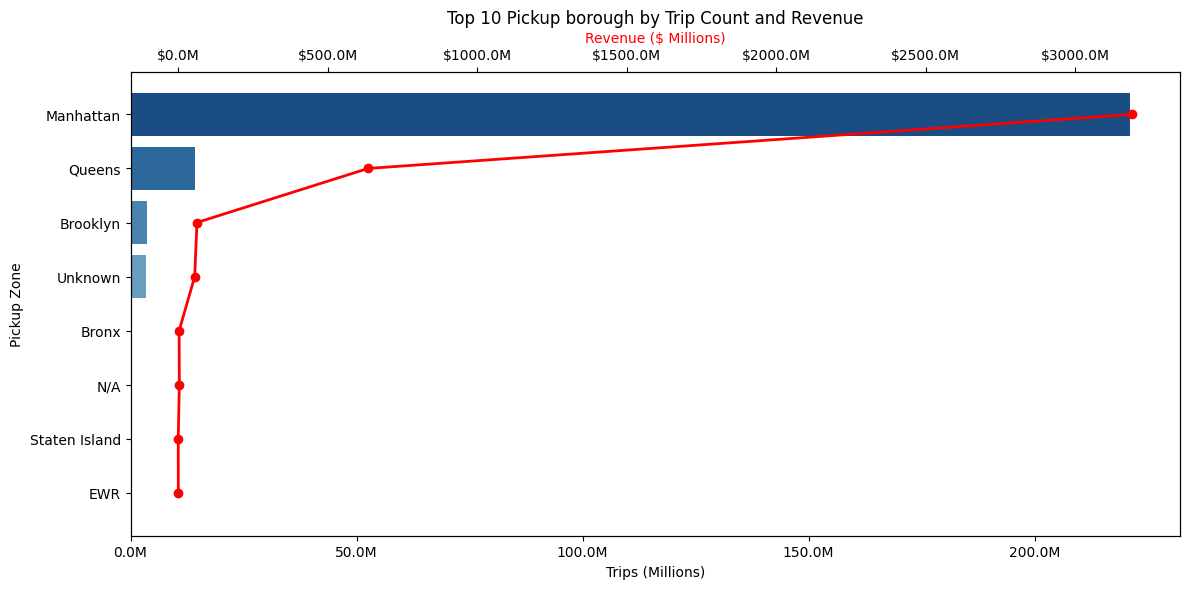

In [18]:

top_pickups = (
    summary_agg_pd
    .groupby("pickup_borough")
    .agg({
        "trip_count": "sum",
        "total_revenue": "sum"
    })
    .reset_index()
    .sort_values("trip_count", ascending=False)
    .head(10)
)

fig, ax1 = plt.subplots(figsize=(12,6))

# Trip count bars
sns.barplot(
    data=top_pickups,
    x="trip_count",
    y="pickup_borough",
    palette="Blues_r",
    ax=ax1
)

ax1.set_xlabel("Trips (Millions)")
ax1.set_ylabel("Pickup Zone")

ax1.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')
)

# Revenue axis
ax2 = ax1.twiny()

ax2.plot(
    top_pickups["total_revenue"],
    top_pickups["pickup_borough"],
    color="red",
    marker="o",
    linewidth=2
)

ax2.set_xlabel("Revenue ($ Millions)", color="red")

ax2.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x/1e6:.1f}M')
)

plt.title("Top 10 Pickup borough by Trip Count and Revenue")
plt.tight_layout()
# Save plot
#plt.savefig("/content/drive/My Drive/Working_data/top_10_pickup_zones_demand_revenue.png", dpi=300)
plt.show()

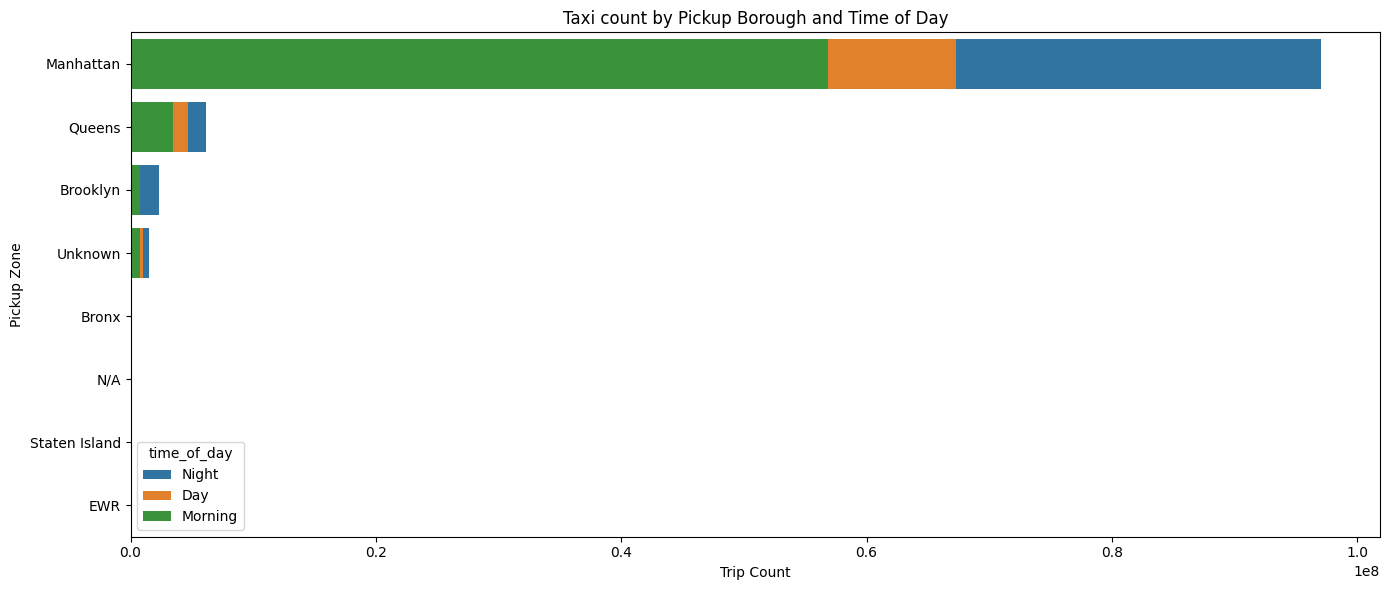

In [19]:
top_zone_day_demand = (
    summary_agg_pd
    .groupby(["pickup_borough", "time_of_day"])["trip_count"]
    .sum()
    .reset_index()
    .sort_values("trip_count", ascending=False)
)

plt.figure(figsize=(14,6))

sns.barplot(
    data=top_zone_day_demand,
    x="trip_count",
    y="pickup_borough",
    hue="time_of_day",
    dodge=False
)

plt.title("Taxi count by Pickup Borough and Time of Day")
plt.xlabel("Trip Count")
plt.ylabel("Pickup Zone")

plt.tight_layout()
plt.show()